<a href="https://colab.research.google.com/github/AlwinJoY007/SML_PROJECT/blob/main/LaLiga_SML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# LaLiga SML Project: Match Outcome Prediction
## Dixon–Coles Model + Bayesian Ideas + Monte Carlo Simulation

**Aim:** Use past LaLiga match results to estimate the probability of a home win, draw, or away win.

This notebook teaches each idea before using it. It includes descriptive statistics, EDA, hypothesis testing (ANOVA, Levene, Kruskal–Wallis, chi-square), Poisson goal modelling, Dixon–Coles, Bayesian concepts, Monte Carlo simulation, and model evaluation.

**Important distinction:** ANOVA and the other statistical tests are used to understand the dataset. They are not the match prediction algorithm. Dixon–Coles is the main score prediction model.

## Roadmap

1. Load and clean historical match data.
2. Explore it using mean, median, variance, standard deviation and graphs.
3. Perform statistical tests: ANOVA, assumption checks, Kruskal–Wallis and chi-square.
4. Understand the Poisson distribution.
5. Fit the Dixon–Coles football model.
6. Understand prior, likelihood, posterior and Bayesian uncertainty.
7. Run Monte Carlo simulations.
8. Evaluate predictions using accuracy, log loss and Brier score.

**Packages:** If needed, run the next cell once.

In [ ]:
# %pip install pandas numpy scipy matplotlib seaborn requests scikit-learn statsmodels

## 1. Import libraries

Libraries are collections of ready-made Python functions. Pandas handles tables, NumPy handles calculations, SciPy/statsmodels provide statistical methods, and Matplotlib/Seaborn create graphs.

In [ ]:
import io, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests
from scipy.stats import poisson, f_oneway, kruskal, chi2_contingency, levene
from scipy.optimize import minimize
from sklearn.metrics import accuracy_score, log_loss, confusion_matrix

np.random.seed(42)
sns.set_theme(style="whitegrid")

## 2. Load LaLiga historical results

A **dataset** is a collection of observations. Here, one row is one completed match.

We use Football-Data CSV files. Important columns:
- `Date`: match date
- `HomeTeam`, `AwayTeam`: teams
- `FTHG`: full-time home goals
- `FTAG`: full-time away goals

The code downloads recent seasons. If the download fails, download the Spain LaLiga CSV files from [Football-Data](https://www.football-data.co.uk/spain.php), combine them, and save them as `laliga_results.csv` in the notebook folder.

In [ ]:
SEASONS = ["2526", "2425", "2324", "2223", "2122", "2021", "1920", "1819"]
URL = "https://www.football-data.co.uk/mmz4281/{}/SP1.csv"

def load_data():
    frames = []
    for season in SEASONS:
        try:
            r = requests.get(URL.format(season), timeout=20)
            r.raise_for_status()
            part = pd.read_csv(io.BytesIO(r.content))
            if {"HomeTeam","AwayTeam","FTHG","FTAG"}.issubset(part.columns):
                frames.append(part)
                print("Loaded", season, len(part), "matches")
        except Exception as e:
            print("Skipped", season, "-", e)
    if frames:
        return pd.concat(frames, ignore_index=True, sort=False)
    if Path("laliga_results.csv").exists():
        return pd.read_csv("laliga_results.csv")
    raise FileNotFoundError("Download LaLiga CSV data from football-data.co.uk/spain.php and save as laliga_results.csv")

raw = load_data()
raw.head()

Loaded 2526 380 matches
Loaded 2425 380 matches
Loaded 2324 380 matches
Loaded 2223 380 matches
Loaded 2122 380 matches
Loaded 2021 380 matches
Loaded 1920 380 matches
Loaded 1819 380 matches


,Div,Date,Time,HomeTeam,AwayTeam,FTHG,FTAG,FTR,HTHG,HTAG,...,BbMx>2.5,BbAv>2.5,BbMx<2.5,BbAv<2.5,BbAH,BbAHh,BbMxAHH,BbAvAHH,BbMxAHA,BbAvAHA
0,SP1,15/08/2025,18:00,Girona,Vallecano,1,3,A,0,3,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,SP1,15/08/2025,20:30,Villarreal,Oviedo,2,0,H,2,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,SP1,16/08/2025,18:30,Mallorca,Barcelona,0,3,A,0,2,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,SP1,16/08/2025,20:30,Alaves,Levante,2,1,H,1,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,SP1,16/08/2025,20:30,Valencia,Sociedad,1,1,D,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 3. Clean the data

**Data cleaning** means handling missing or incorrectly formatted values. We convert dates and goals to the correct types, remove incomplete rows, and sort matches by date.

In [ ]:
matches = raw.copy()
matches["Date"] = pd.to_datetime(matches["Date"], dayfirst=True, errors="coerce")
for col in ["FTHG", "FTAG"]:
    matches[col] = pd.to_numeric(matches[col], errors="coerce")
matches = matches.dropna(subset=["Date","HomeTeam","AwayTeam","FTHG","FTAG"])
matches = matches[(matches["FTHG"] >= 0) & (matches["FTAG"] >= 0)].copy()
matches["FTHG"] = matches["FTHG"].astype(int)
matches["FTAG"] = matches["FTAG"].astype(int)
matches = matches.sort_values("Date").drop_duplicates(
    ["Date","HomeTeam","AwayTeam"]
).reset_index(drop=True)
matches["TotalGoals"] = matches["FTHG"] + matches["FTAG"]
matches["Result"] = np.select(
    [matches.FTHG > matches.FTAG, matches.FTHG == matches.FTAG],
    ["Home Win","Draw"], default="Away Win"
)
print("Matches:", len(matches))
print("Date range:", matches.Date.min(), "to", matches.Date.max())
print("Teams:", len(set(matches.HomeTeam) | set(matches.AwayTeam)))
display(matches.head())

Matches: 3040
Date range: 2018-08-17 00:00:00 to 2026-05-24 00:00:00
Teams: 28


,Div,Date,Time,HomeTeam,AwayTeam,FTHG,FTAG,FTR,HTHG,HTAG,...,BbMx<2.5,BbAv<2.5,BbAH,BbAHh,BbMxAHH,BbAvAHH,BbMxAHA,BbAvAHA,TotalGoals,Result
0,SP1,2018-08-17,NaN,Betis,Levante,0,3,A,0,1,...,2.15,2.06,20.0,-0.75,1.89,1.85,2.07,2.00,3,Away Win
1,SP1,2018-08-17,NaN,Girona,Valladolid,0,0,D,0,0,...,1.78,1.71,20.0,-0.75,2.06,2.01,1.90,1.85,0,Draw
2,SP1,2018-08-18,NaN,Celta,Espanol,1,1,D,0,1,...,1.84,1.76,18.0,-0.75,2.26,2.18,1.74,1.71,2,Draw
3,SP1,2018-08-18,NaN,Barcelona,Alaves,3,0,H,0,0,...,3.40,3.18,19.0,-2.50,1.95,1.91,2.00,1.95,3,Home Win
4,SP1,2018-08-18,NaN,Villarreal,Sociedad,1,2,A,1,1,...,1.88,1.81,18.0,-0.25,1.76,1.74,2.23,2.14,3,Away Win


## 4. Descriptive statistics

Descriptive statistics summarise the data:
- **Mean:** average value.
- **Median:** middle value after sorting.
- **Variance:** average squared spread around the mean.
- **Standard deviation:** typical spread, in the original unit (goals).
- **Minimum / maximum:** smallest / largest observed value.

,FTHG,FTAG,TotalGoals
count,3040.000000,3040.000000,3040.000000
mean,1.455592,1.112829,2.568421
std,1.220372,1.065832,1.618600
min,0.000000,0.000000,0.000000
25%,1.000000,0.000000,1.000000
50%,1.000000,1.000000,2.000000
75%,2.000000,2.000000,3.000000
max,8.000000,7.000000,10.000000


Home goals mean: 1.46
Away goals mean: 1.11
Total goals variance: 2.62
Total goals standard deviation: 1.62


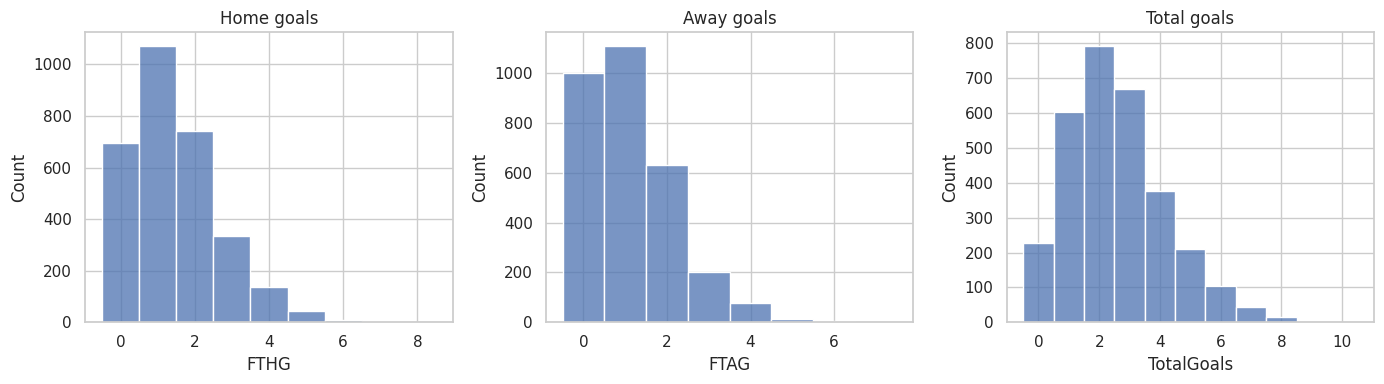

In [ ]:
display(matches[["FTHG","FTAG","TotalGoals"]].describe())
print("Home goals mean:", round(matches.FTHG.mean(),2))
print("Away goals mean:", round(matches.FTAG.mean(),2))
print("Total goals variance:", round(matches.TotalGoals.var(),2))
print("Total goals standard deviation:", round(matches.TotalGoals.std(),2))

fig, axes = plt.subplots(1,3,figsize=(14,4))
sns.histplot(matches.FTHG, discrete=True, ax=axes[0]); axes[0].set_title("Home goals")
sns.histplot(matches.FTAG, discrete=True, ax=axes[1]); axes[1].set_title("Away goals")
sns.histplot(matches.TotalGoals, discrete=True, ax=axes[2]); axes[2].set_title("Total goals")
plt.tight_layout(); plt.show()

## 5. Exploratory Data Analysis (EDA)

**EDA** means exploring data with summaries and graphs before modelling. We first look at the historical proportions of home wins, draws and away wins. These are past frequencies, not predictions for a future match.

,Percentage
Result,
Home Win,45.0
Away Win,28.0
Draw,27.0


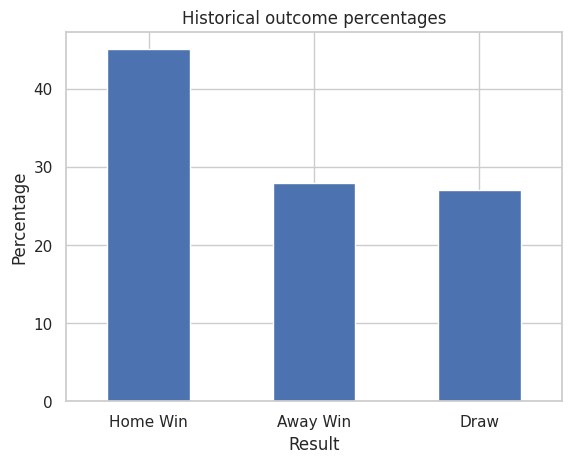

,count,mean,std
HomeTeam,,,
Barcelona,152,2.45,1.59
Real Madrid,152,2.18,1.40
Ath Madrid,152,1.96,1.27
Villarreal,152,1.95,1.37
Girona,95,1.61,1.52
Betis,152,1.57,1.06
Levante,95,1.49,1.13
Ath Bilbao,152,1.47,1.29
Sevilla,152,1.45,1.17


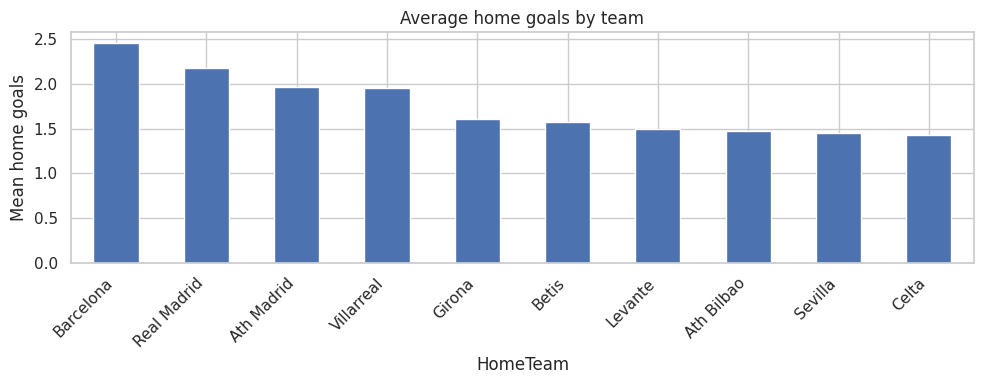

In [ ]:
display((matches.Result.value_counts(normalize=True)*100).round(1).rename("Percentage").to_frame())
(matches.Result.value_counts(normalize=True)*100).plot(kind="bar", title="Historical outcome percentages")
plt.ylabel("Percentage"); plt.xticks(rotation=0); plt.show()

team_home = matches.groupby("HomeTeam").FTHG.agg(["count","mean","std"]).sort_values("mean",ascending=False)
display(team_home.head(10).round(2))
team_home["mean"].head(10).plot(kind="bar",figsize=(10,4),title="Average home goals by team")
plt.ylabel("Mean home goals"); plt.xticks(rotation=45,ha="right"); plt.tight_layout(); plt.show()

## 6. Hypothesis testing

A **hypothesis test** uses sample data to assess a claim.

- **Null hypothesis (H₀):** usually says there is no difference.
- **Alternative hypothesis (H₁):** says a difference exists.
- **Significance level (α):** often 0.05.
- **p-value:** probability of results this extreme (or more extreme), assuming H₀ is true.

If p-value < 0.05, we commonly reject H₀. This does not prove causation or mean there is a 95% chance H₁ is true.

### 6.1 One-way ANOVA

**ANOVA = Analysis of Variance.** It compares the means of three or more groups.

Question: do teams have different average home goals?

- H₀: all teams have the same population mean home goals.
- H₁: at least one team's mean is different.

ANOVA assumptions: independent observations, approximately normal residuals within groups, and similar group variances. Football goal counts are discrete and often non-normal, so interpret the result carefully.

In [ ]:
home_groups = [
    g.FTHG.values for team,g in matches.groupby("HomeTeam") if len(g) >= 10
]
f_stat, anova_p = f_oneway(*home_groups)
print("ANOVA F-statistic:", round(f_stat,3))
print("ANOVA p-value:", anova_p)
print("Decision:", "Reject H0: evidence at least one mean differs" if anova_p < 0.05
      else "Do not reject H0: insufficient evidence of different means")

ANOVA F-statistic: 13.295
ANOVA p-value: 5.549428256799568e-56
Decision: Reject H0: evidence at least one mean differs


### 6.2 Check assumptions and use Kruskal–Wallis

**Levene's test** checks whether group variances are similar. A small p-value suggests unequal variances.

**Kruskal–Wallis** is a non-parametric alternative that compares group ranks/distributions. It does not directly test equality of means, but can be useful when ANOVA assumptions are doubtful.

In [ ]:
lev_stat, lev_p = levene(*home_groups)
kw_stat, kw_p = kruskal(*home_groups)
print("Levene p-value (equal variance check):", lev_p)
print("Kruskal-Wallis statistic:", round(kw_stat,3))
print("Kruskal-Wallis p-value:", kw_p)
print("Kruskal-Wallis:", "Evidence of group differences" if kw_p < 0.05 else "Insufficient evidence of group differences")

Levene p-value (equal variance check): 1.4179930062308947e-12
Kruskal-Wallis statistic: 277.501
Kruskal-Wallis p-value: 2.1226977721470944e-43
Kruskal-Wallis: Evidence of group differences


### 6.3 Chi-square test of independence

A **chi-square test** checks whether two categorical variables are associated. We demonstrate it by checking whether goal-total categories (0–1, 2–3, 4+) have different frequencies across match outcomes.

This is an exploratory association test, not proof that one variable causes another. The expected cell counts should also be checked; very small expected counts can make the chi-square approximation unreliable.

In [ ]:
matches["GoalBand"] = pd.cut(matches.TotalGoals, bins=[-1,1,3,30], labels=["0-1","2-3","4+"])
contingency = pd.crosstab(matches.Result, matches.GoalBand)
display(contingency)
chi2, chi_p, dof, expected = chi2_contingency(contingency)
print("Chi-square statistic:", round(chi2,3))
print("Degrees of freedom:", dof)
print("p-value:", chi_p)
print("Smallest expected cell count:", round(expected.min(),2))

GoalBand,0-1,2-3,4+
Result,,,
Away Win,238,417,195
Draw,227,412,182
Home Win,364,633,372


Chi-square statistic: 8.929
Degrees of freedom: 4
p-value: 0.06289181063784609
Smallest expected cell count: 202.28


## 7. Poisson distribution: modelling goal counts

The **Poisson distribution** models the number of times an event occurs in a fixed interval. In football, the event is a goal and the interval is one match.

Its parameter λ (lambda) is the expected goal count. If λ = 1.5, the distribution gives probabilities of scoring 0, 1, 2, 3, etc. goals.

This is the basic statistical idea used by the football score model.

,Goals,Probability
0,0,22.31%
1,1,33.47%
2,2,25.10%
3,3,12.55%
4,4,4.71%
5,5,1.41%
6,6,0.35%


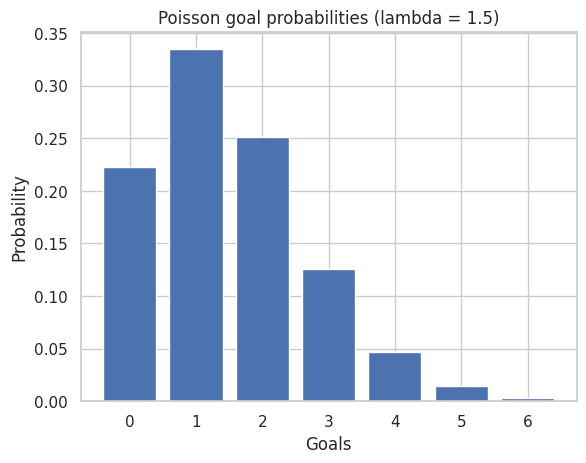

In [ ]:
lam = 1.5
goals = np.arange(0,7)
prob = poisson.pmf(goals, lam)
display(pd.DataFrame({"Goals":goals,"Probability":prob}).style.format({"Probability":"{:.2%}"}))
plt.bar(goals,prob); plt.xlabel("Goals"); plt.ylabel("Probability")
plt.title("Poisson goal probabilities (lambda = 1.5)"); plt.show()

## 8. Dixon–Coles model

The Dixon–Coles model is designed for football scores. It estimates:
- **Attack strength:** how well a team scores.
- **Defence strength:** how well a team prevents goals.
- **Home advantage:** scoring advantage associated with playing at home.
- **Overall scoring level:** the league-wide scoring baseline.

Expected goals:

\[
\lambda_H=e^{\mu+h+attack_H-defence_A}
\]

\[
\lambda_A=e^{\mu+attack_A-defence_H}
\]

The model starts with Poisson goal probabilities and applies a Dixon–Coles correction to 0–0, 0–1, 1–0 and 1–1 scorelines.

We give recent matches more influence using **time decay**. The half-life is the number of days after which a match's weight is halved.

In [ ]:
def dc_tau(x,y,lh,la,rho):
    if x==0 and y==0: return max(1e-9,1-lh*la*rho)
    if x==0 and y==1: return max(1e-9,1+lh*rho)
    if x==1 and y==0: return max(1e-9,1+la*rho)
    if x==1 and y==1: return max(1e-9,1-rho)
    return 1.0

def fit_dc(data, half_life=180, prior_sd=0.7):
    data=data.sort_values("Date").reset_index(drop=True)
    teams=sorted(set(data.HomeTeam)|set(data.AwayTeam))
    idx={t:i for i,t in enumerate(teams)}
    hi=data.HomeTeam.map(idx).to_numpy(); ai=data.AwayTeam.map(idx).to_numpy()
    hg=data.FTHG.to_numpy(); ag=data.FTAG.to_numpy()
    age=(data.Date.max()-data.Date).dt.days.to_numpy()
    w=np.exp(-np.log(2)*age/half_life)
    n=len(teams)
    initial=np.zeros(2+2*n+1); initial[0]=np.log(1.25); initial[1]=0.15; initial[-1]=-0.05

    def objective(p):
        mu,h=p[:2]
        attack=p[2:2+n]-np.mean(p[2:2+n])
        defence=p[2+n:2+2*n]-np.mean(p[2+n:2+2*n])
        rho=p[-1]
        lh=np.exp(np.clip(mu+h+attack[hi]-defence[ai],-4,3))
        la=np.exp(np.clip(mu+attack[ai]-defence[hi],-4,3))
        ll=poisson.logpmf(hg,lh)+poisson.logpmf(ag,la)
        tau=np.array([dc_tau(x,y,a,b,rho) for x,y,a,b in zip(hg,ag,lh,la)])
        ll += np.log(tau)
        # Gaussian regularisation acts like a simple prior on team strengths.
        penalty=0.5*np.sum(attack**2+defence**2)/prior_sd**2
        penalty += 0.5*((mu-np.log(1.25))/1.0)**2 + 0.5*(h/0.5)**2 + 0.5*(rho/0.15)**2
        return -(np.sum(w*ll)-penalty)

    bounds=[(None,None)]*(len(initial)-1)+[(-0.25,0.25)]
    result=minimize(objective,initial,method="L-BFGS-B",bounds=bounds,
                    options={"maxiter":1500})
    p=result.x.copy()
    p[2:2+n]-=p[2:2+n].mean()
    p[2+n:2+2*n]-=p[2+n:2+2*n].mean()
    return {"params":p,"teams":teams,"index":idx,"success":result.success,"message":result.message}

model=fit_dc(matches)
print("Model fitted:",model["success"])
print(model["message"])

Model fitted: True
CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH


## 9. Bayesian modelling: prior, likelihood and posterior

Bayesian inference updates uncertainty about unknown values using observed data.

\[
P(\theta\mid D) \propto P(D\mid\theta)P(\theta)
\]

- **Prior:** plausible values before seeing the current data.
- **Likelihood:** how well a parameter value explains the observed matches.
- **Posterior:** updated distribution after combining prior and data.
- **MAP estimate:** the parameter value with the highest posterior density.

In our Dixon–Coles fitting code, Gaussian regularisation acts like a simple prior and the optimiser finds a MAP estimate. This notebook does **not** run full Bayesian MCMC. A full Bayesian extension would sample the posterior and check convergence (for example, R-hat and effective sample size).

In [ ]:
n=len(model["teams"]); p=model["params"]
strengths=pd.DataFrame({
    "Team":model["teams"],
    "Attack strength":p[2:2+n],
    "Defence strength":p[2+n:2+2*n]
}).sort_values("Attack strength",ascending=False)
display(strengths.round(3).head(10))

,Team,Attack strength,Defence strength
4,Barcelona,0.637,0.327
21,Real Madrid,0.451,0.345
27,Villarreal,0.407,0.052
3,Ath Madrid,0.273,0.156
5,Betis,0.210,0.067
23,Sociedad,0.174,-0.120
7,Celta,0.146,0.049
9,Elche,0.050,-0.089
17,Levante,0.033,-0.100
24,Valencia,0.024,0.011


## 10. Create a scoreline probability table

A **scoreline probability table** gives the probability of each possible score, such as 0–0, 1–0, 1–1 or 2–1.

We calculate expected goals for the selected teams, create a grid of Poisson probabilities, apply the Dixon–Coles low-score correction, and normalise the grid so all its probabilities add to 1.

Available team names:
['Alaves', 'Almeria', 'Ath Bilbao', 'Ath Madrid', 'Barcelona', 'Betis', 'Cadiz', 'Celta', 'Eibar', 'Elche', 'Espanol', 'Getafe', 'Girona', 'Granada', 'Huesca', 'Las Palmas', 'Leganes', 'Levante', 'Mallorca', 'Osasuna', 'Oviedo', 'Real Madrid', 'Sevilla', 'Sociedad', 'Valencia', 'Valladolid', 'Vallecano', 'Villarreal']
Expected home goals: 1.99
Expected away goals: 1.23


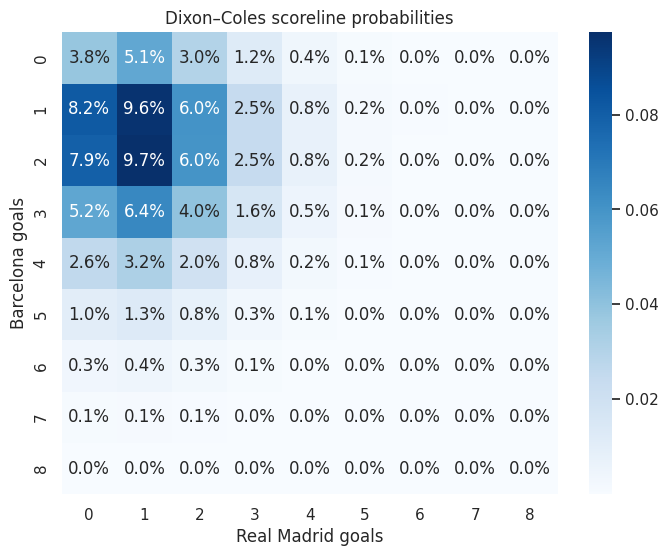

In [ ]:
def expected_goals(home,away,model):
    if home not in model["index"] or away not in model["index"]:
        raise ValueError("Team not found. Check exact spelling in model['teams'].")
    p=model["params"]; n=len(model["teams"])
    mu,h=p[:2]
    attack=p[2:2+n]-p[2:2+n].mean()
    defence=p[2+n:2+2*n]-p[2+n:2+2*n].mean()
    i=model["index"][home]; j=model["index"][away]
    lh=np.exp(mu+h+attack[i]-defence[j])
    la=np.exp(mu+attack[j]-defence[i])
    return float(lh),float(la),float(p[-1])

def score_grid(lh,la,rho,max_goals=8):
    g=np.arange(max_goals+1)
    grid=np.outer(poisson.pmf(g,lh),poisson.pmf(g,la))
    for x in (0,1):
        for y in (0,1):
            grid[x,y]*=dc_tau(x,y,lh,la,rho)
    return grid/grid.sum()

print("Available team names:")
print(model["teams"])

# Change to exact team names from the printed list.
HOME_TEAM="Barcelona"
AWAY_TEAM="Real Madrid"
lh,la,rho=expected_goals(HOME_TEAM,AWAY_TEAM,model)
grid=score_grid(lh,la,rho)
print("Expected home goals:",round(lh,2))
print("Expected away goals:",round(la,2))

plt.figure(figsize=(8,6))
sns.heatmap(grid,annot=True,fmt=".1%",cmap="Blues",
            xticklabels=range(9),yticklabels=range(9))
plt.xlabel(AWAY_TEAM+" goals"); plt.ylabel(HOME_TEAM+" goals")
plt.title("Dixon–Coles scoreline probabilities"); plt.show()

## 11. Home win, draw and away win probabilities

We add up the scoreline probabilities:
- Home win: home goals are greater than away goals.
- Draw: both goal counts are equal.
- Away win: away goals are greater than home goals.

,Probability (%)
Barcelona win,55.13
Draw,21.30
Real Madrid win,23.57


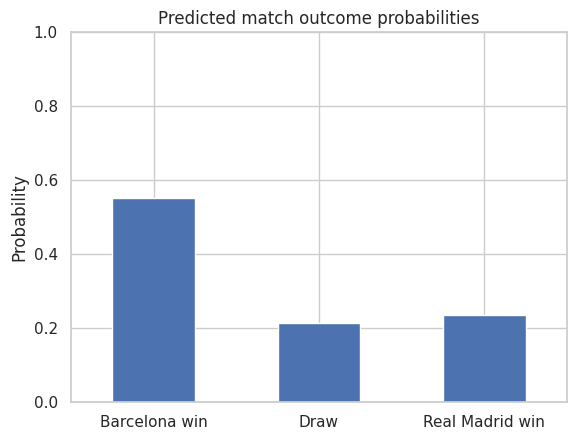

In [ ]:
p_home=np.tril(grid,-1).sum()
p_draw=np.trace(grid)
p_away=np.triu(grid,1).sum()
outcomes=pd.Series({
    HOME_TEAM+" win":p_home,
    "Draw":p_draw,
    AWAY_TEAM+" win":p_away
})
display((outcomes*100).round(2).to_frame("Probability (%)"))
outcomes.plot(kind="bar",ylim=(0,1),title="Predicted match outcome probabilities")
plt.ylabel("Probability"); plt.xticks(rotation=0); plt.show()

## 12. Monte Carlo simulation

Monte Carlo simulation repeats a random experiment many times.

For each simulated match, we randomly select a scoreline using the scoreline probability table. We repeat this thousands of times and count home wins, draws and away wins.

The fraction of each result estimates its probability. More simulations reduce random simulation noise, but cannot fix poor data or a poorly specified model.

In [ ]:
def monte_carlo(grid, simulations=50000, seed=42):
    rng=np.random.default_rng(seed)
    selected=rng.choice(grid.size,size=simulations,p=grid.ravel())
    home_goals=selected//grid.shape[1]
    away_goals=selected%grid.shape[1]
    result=np.where(home_goals>away_goals,"Home Win",
            np.where(home_goals==away_goals,"Draw","Away Win"))
    percentages=pd.Series(result).value_counts(normalize=True)*100
    scores=pd.DataFrame({"Home goals":home_goals,"Away goals":away_goals})
    top=scores.value_counts().head(10).rename("Count").reset_index()
    top["Probability (%)"]=top["Count"]/simulations*100
    return percentages,top

mc_results,top_scores=monte_carlo(grid)
display(mc_results.round(2).to_frame("Monte Carlo probability (%)"))
display(top_scores)

,Monte Carlo probability (%)
Home Win,55.19
Away Win,23.34
Draw,21.48


,Home goals,Away goals,Count,Probability (%)
0,2,1,4928,9.856
1,1,1,4804,9.608
2,1,0,4059,8.118
3,2,0,3865,7.730
4,3,1,3299,6.598
5,2,2,3042,6.084
6,1,2,2964,5.928
7,3,0,2665,5.330
8,0,1,2521,5.042
9,3,2,1991,3.982


## 13. Evaluate the model on later matches

A model must be tested on matches it did not train on.

- **Training set:** earlier matches used to fit parameters.
- **Test set:** later matches held back for evaluation.
- **Chronological split:** keeps the time order, avoiding the mistake of using future matches to predict past matches.

Metrics:
- **Accuracy:** proportion of matches where the most likely result was correct.
- **Log loss:** evaluates probability quality; lower is better and confident wrong predictions are penalised.
- **Brier score:** average squared difference between predicted probabilities and the actual result encoded as 0/1; lower is better.

This is a single holdout evaluation. A stronger study would repeat it over multiple rolling time periods.

In [ ]:
def label_result(h,a):
    return 0 if h>a else (1 if h==a else 2)

def evaluate(data,test_fraction=0.20):
    data=data.sort_values("Date").reset_index(drop=True)
    cut=int(len(data)*(1-test_fraction))
    train=data.iloc[:cut]
    test=data.iloc[cut:]
    fitted=fit_dc(train)
    probs=[]; actual=[]
    for _,row in test.iterrows():
        home,away=row.HomeTeam,row.AwayTeam
        if home not in fitted["index"] or away not in fitted["index"]:
            continue
        a,b,r=expected_goals(home,away,fitted)
        g=score_grid(a,b,r)
        probs.append([np.tril(g,-1).sum(),np.trace(g),np.triu(g,1).sum()])
        actual.append(label_result(row.FTHG,row.FTAG))
    probs=np.asarray(probs); actual=np.asarray(actual)
    onehot=np.eye(3)[actual]
    return {
        "training matches":len(train),
        "test matches":len(actual),
        "accuracy":accuracy_score(actual,probs.argmax(axis=1)),
        "log loss":log_loss(actual,probs,labels=[0,1,2]),
        "Brier score":np.mean(np.sum((probs-onehot)**2,axis=1)),
        "confusion matrix":confusion_matrix(actual,probs.argmax(axis=1))
    }

evaluation=evaluate(matches)
for key,value in evaluation.items():
    print(key,":\n",value)

training matches :
 2432
test matches :
 570
accuracy :
 0.5157894736842106
log loss :
 0.9910996914253088
Brier score :
 0.5883722746063138
confusion matrix :
 [[221   0  46]
 [ 97   0  44]
 [ 88   1  73]]


## 14. Conclusion and limitations

### What we learned
- Descriptive statistics and EDA summarise historical match patterns.
- ANOVA compares means across several groups; Levene checks variance similarity; Kruskal–Wallis is a non-parametric alternative.
- Chi-square tests association between categorical variables.
- Poisson distribution models goal counts.
- Dixon–Coles estimates football scoreline probabilities and adjusts low scores.
- Bayesian ideas represent uncertainty using prior, likelihood and posterior.
- Monte Carlo repeatedly samples possible scorelines to estimate outcome probabilities.
- Accuracy, log loss and Brier score evaluate predictions on unseen matches.

### Limitations
1. Historical scores do not include injuries, suspensions, lineups or tactical changes.
2. ANOVA assumptions may not hold perfectly for discrete football goal data.
3. This notebook uses MAP estimation with prior regularisation; it does not perform full Bayesian MCMC.
4. Monte Carlo simulation does not guarantee correct predictions.
5. Use multiple chronological test periods and compare against a simple baseline for a stronger academic evaluation.

### Possible future work
Add reliable team news or expected-goals data, compare with an independent Poisson baseline, implement full Bayesian MCMC, and create a dashboard for fixture selection.

## 15. Export prediction results

Run this cell after completing the prediction sections. It saves the scoreline grid and outcome probabilities as CSV files.

In [ ]:
pd.DataFrame(grid).to_csv("laliga_scoreline_probabilities.csv",index=False)
(outcomes*100).rename("Probability_Percent").to_csv("laliga_outcome_probabilities.csv")
print("Saved laliga_scoreline_probabilities.csv and laliga_outcome_probabilities.csv")

Saved laliga_scoreline_probabilities.csv and laliga_outcome_probabilities.csv
